# Music Classification and Wine Clustering

This notebook explores two machine-learning workflows: predicting music genres from numerical track features, and grouping wines by selected chemical measurements. The music analysis compares a support vector classifier with a random forest, then examines where the predictions fail. The wine analysis uses standardized features, K-means, and principal component analysis to explore groups in the data.

The sections follow the workflow from data inspection through preprocessing, modelling, evaluation, and interpretation. The model settings come from an exploratory analysis; the reported classification scores are descriptive results for one split rather than a final, independently validated performance estimate.

**Inputs:** `data/music_genres.csv`, `data/music_unlabelled.csv`, and `data/wine_features.csv`. The final music predictions are written to `outputs/music_predictions.csv`. Dataset schemas and setup instructions are documented in the README.


**Music-genre classification**

The labelled music dataset pairs track attributes with a `music_genre` target. A supervised classifier learns relationships between those attributes and the supplied genre labels, then predicts labels for new tracks. There are ten target classes in this dataset.

The workflow reserves part of the labelled data for evaluation and fits the models on the remaining records. Evaluating predictions on records not used to fit the model provides a view of generalization. However, repeatedly using the same evaluation split to choose settings can bias that view; the model-selection limitation is discussed alongside the results.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 524
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

MusicDataset = pd.read_csv(DATA_DIR / "music_genres.csv")
unlabelled_music = pd.read_csv(DATA_DIR / "music_unlabelled.csv")
MusicDataset.head()


,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre
0,77382,Sheena Ringo,獣ゆく細道,48,0.01340,0.423,224053,0.799,0.000004,0.1470,-4.227,0.0447,124.626,0.5560,1
1,23554,empty_field,Fossil Roo,22,0.86200,0.590,151067,0.221,0.468000,0.0736,-16.338,0.0383,129.984,0.0331,1
2,82886,The Beatles,Dear Prudence - 2018 Mix,62,0.09040,0.395,234973,0.538,0.000453,0.0685,-10.300,0.0456,150.785,0.3690,9
3,37772,Pink Floyd,Have a Cigar,64,0.40700,0.454,307733,0.650,0.049800,0.5890,-10.191,0.0437,120.154,0.7200,9
4,80191,A-Trak,Push,43,0.00145,0.642,213512,0.877,0.002790,0.0984,-2.878,0.0450,126.058,0.4960,5


In [2]:
label = MusicDataset['music_genre']
features = MusicDataset.drop(['instance_id', 'artist_name', 'track_name', 'music_genre'], axis = 1)

**Feature selection**

The target column is separated from the input features. The baseline excludes `instance_id`, `artist_name`, and `track_name` so that the models use numerical track attributes rather than identifiers or raw text. This is a modelling choice, not evidence that artist or title information has no predictive value. Using those fields would require a different representation and an evaluation design that checks for artist-level leakage.


In [3]:
label.value_counts()

music_genre
2    2667
3    2626
6    2617
0    2616
9    2593
4    2586
7    2578
1    2575
5    2574
8    2526
Name: count, dtype: int64

In [4]:
label.value_counts().max()

2667

In [5]:
label.value_counts().min()

2526

In [6]:
MusicDataset.isnull().sum()

instance_id         0
artist_name         0
track_name          0
popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
music_genre         0
dtype: int64

In [7]:
MusicDataset.dtypes

instance_id           int64
artist_name          object
track_name           object
popularity            int64
acousticness        float64
danceability        float64
duration_ms           int64
energy              float64
instrumentalness    float64
liveness            float64
loudness            float64
speechiness         float64
tempo               float64
valence             float64
music_genre           int64
dtype: object

In [8]:
features.describe()

,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence
count,25958.000000,25958.000000,25958.000000,2.595800e+04,25958.000000,25958.000000,25958.000000,25958.000000,25958.000000,25958.000000,25958.000000
mean,44.168541,0.307858,0.557978,2.454655e+05,0.599596,0.182954,0.193972,-9.167320,0.094058,120.003122,0.458558
std,15.547882,0.342093,0.178840,1.105926e+05,0.265468,0.326709,0.162042,6.180744,0.102968,30.612044,0.247895
min,0.000000,0.000000,0.059600,1.631600e+04,0.000792,0.000000,0.009670,-47.046000,0.022300,34.347000,0.000000
25%,34.000000,0.020300,0.442000,1.904285e+05,0.430000,0.000000,0.096900,-10.898000,0.035900,94.986000,0.260000
50%,45.000000,0.146000,0.569000,2.275015e+05,0.645000,0.000167,0.126000,-7.293000,0.048700,119.848500,0.451000
75%,55.000000,0.553000,0.686000,2.758930e+05,0.817000,0.158000,0.243000,-5.185000,0.098575,140.493750,0.650000
max,99.000000,0.996000,0.986000,4.497994e+06,0.999000,0.996000,1.000000,3.744000,0.942000,220.276000,0.989000


**Dataset profile**

The class-count outputs show similar numbers of tracks per genre, with no severe class imbalance in this sample. The missing-value check reports no pandas null values. That check does not rule out placeholder strings or other data-quality problems; for example, the raw artist field contains a placeholder value, although that field is excluded from the numerical baseline.

The retained predictors are integer and floating-point measurements. Their ranges differ substantially, particularly for duration and bounded audio attributes. The summary statistics provide the context for choosing preprocessing for the distance-sensitive classifier.


In [9]:
features_train, features_test, label_train, label_test = train_test_split(
    features, label, test_size=0.20, random_state=RANDOM_STATE, stratify=label
)

**Training and evaluation split**

The split uses 80% of records for fitting and 20% for evaluation. A fixed random seed makes the partition repeatable. Stratification approximately preserves the existing class proportions in both subsets; it does not rebalance the dataset to equal class sizes.


**A multiclass prediction task**

Each track receives one of ten genre labels, making this a multiclass classification problem. A binary classifier would instead choose between two labels, such as two explicitly defined track categories. Here, a confusion matrix and a class-wise report help show which of the ten genres are difficult to distinguish.


**Scaling the numerical inputs**

An RBF support vector classifier depends on distances between feature vectors. A feature with a large numerical range can dominate those distances even if it is not the most informative predictor. Scaling helps control this effect. The random forest is fitted on the original numerical features because tree split rules do not require the same distance-based scaling.


In [10]:
sc = QuantileTransformer(
    n_quantiles=min(2500, len(features_train)), random_state=RANDOM_STATE
)
features_train_scaled = sc.fit_transform(features_train)
features_test_scaled = sc.transform(features_test)


The preprocessing step is fitted only on the training subset. The same fitted transformation is then applied to the evaluation subset and the unlabelled tracks. This keeps the feature representation consistent without estimating a new transformation from evaluation or prediction inputs.


A quantile transformation maps each feature using an estimated cumulative distribution, producing an approximately uniform marginal distribution with the default settings. It can reduce the influence of extreme magnitudes, but it also changes feature spacing and can affect relationships between features.

This transformer was selected during manual exploration of preprocessing options. The notebook does not contain a cross-validated comparison establishing that it is universally the best choice. The fixed seed controls its sampling randomness for repeatable reruns in the documented environment.


**Support vector classifier**

A support vector machine learns a decision boundary using training examples near the class margins. The parameter `C` controls the tradeoff between margin width and penalties for training errors. For this multiclass task, scikit-learn's `SVC` handles the necessary pairwise classification problems internally.


The RBF kernel compares examples through a nonlinear similarity function, allowing decision boundaries that would not be linear in the original feature space. The kernel computation avoids constructing an explicit high-dimensional feature matrix. Its `gamma` parameter controls how quickly similarity falls with distance.


In [11]:
svc=SVC(C = 5, gamma = 'scale', kernel = 'rbf', class_weight = 'balanced', random_state = RANDOM_STATE)

svc.fit(features_train_scaled, label_train)

label_predict_svc = svc.predict(features_test_scaled)

The classifier uses an RBF kernel, `C=5`, `gamma='scale'`, and balanced class weights. These settings were selected through manual experimentation with accuracy as a guide. They are exploratory choices rather than the result of a recorded, systematic hyperparameter search. Balanced weights adjust for the small differences in class frequencies.


In [12]:
rfc = RandomForestClassifier(
n_estimators = 550,
min_samples_split = 20,
max_depth = None,
class_weight='balanced',
random_state = RANDOM_STATE
)

rfc.fit(features_train, label_train)
label_predict_rfc = rfc.predict(features_test)


**Random forest baseline**

The random forest combines predictions from multiple decision trees. This configuration uses 550 trees, a minimum of 20 samples to split a node, unrestricted tree depth, and balanced class weights. Its parameters were also selected manually. Comparing it with the support vector classifier provides a second modelling approach, but does not establish globally optimal settings for either model.


In [13]:
print(f"Random forest evaluation accuracy: {accuracy_score(label_test, label_predict_rfc):.4f}")
print(f"Support vector evaluation accuracy: {accuracy_score(label_test, label_predict_svc):.4f}")


Random forest evaluation accuracy: 0.5797
Support vector evaluation accuracy: 0.5934


In [14]:
confusion_matrix_svm = confusion_matrix(label_test, label_predict_svc)
confusion_matrix_svm

array([[202,   9,  11,   0,  59,  33,  45,  31,  23, 110],
       [ 15, 382,  18,  50,  18,  15,   0,  13,   2,   2],
       [ 17,  57, 293,  11,  46,  25,   2,  55,   1,  27],
       [ 13,  12,  17, 450,   3,  11,   0,  17,   0,   2],
       [ 28,  12,  17,   1, 337,   4,   9,  26,   7,  76],
       [ 32,  26,  21,   6,  12, 322,  16,  60,   3,  17],
       [ 24,   0,   1,   0,   4,   6, 252,   5, 210,  21],
       [ 23,   7,  53,  42,  26,  56,  10, 278,   4,  17],
       [ 20,   0,   1,   0,   3,   4, 201,   3, 209,  64],
       [ 41,   2,   4,   1,  56,   4,  13,  17,  25, 356]], dtype=int64)

In [15]:
confusion_matrix_rfc = confusion_matrix(label_test, label_predict_rfc)
confusion_matrix_rfc

array([[176,   5,  10,   0,  62,  36,  41,  38,  29, 126],
       [ 11, 386,  26,  46,  18,  14,   1,   8,   0,   5],
       [ 18,  50, 289,  14,  49,  33,   3,  51,   0,  27],
       [ 12,   7,  18, 450,   1,  10,   0,  25,   0,   2],
       [ 22,  11,  22,   0, 312,   3,   9,  22,   8, 108],
       [ 24,  23,  35,   6,  14, 321,  16,  51,   6,  19],
       [ 12,   0,   1,   0,   4,   4, 244,   5, 224,  29],
       [ 12,   5,  41,  46,  28,  59,  16, 276,   5,  28],
       [ 15,   0,   0,   0,   2,   2, 240,   2, 166,  78],
       [ 35,   2,   1,   1,  34,   2,  16,  15,  23, 390]], dtype=int64)

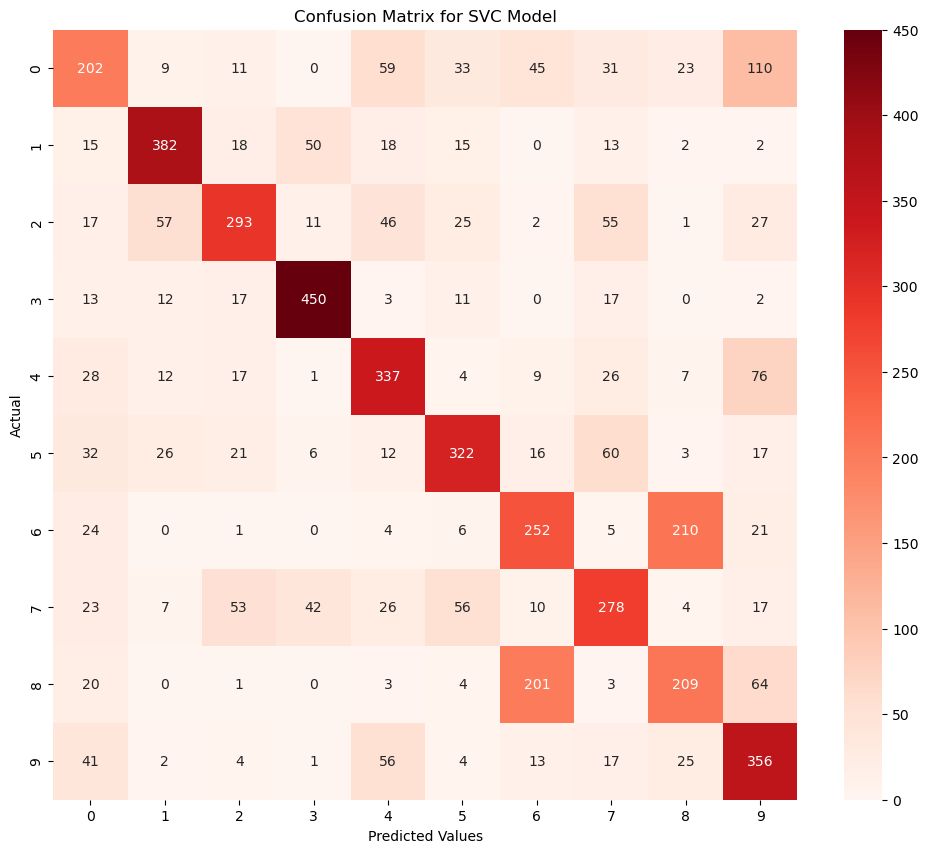

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(confusion_matrix(label_test, label_predict_svc), annot=True, fmt='d', cmap = "Reds")
plt.title("Confusion Matrix for SVC Model")
plt.xlabel("Predicted Values")
plt.ylabel("Actual")
plt.show()

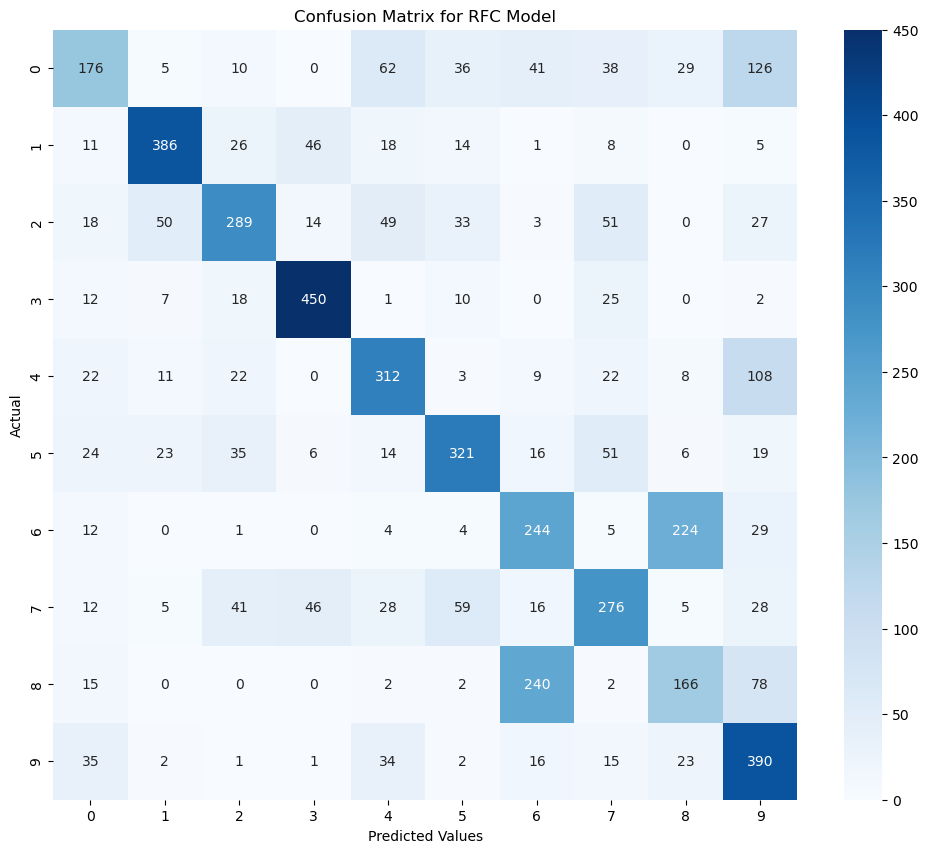

In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(confusion_matrix(label_test, label_predict_rfc), annot=True, fmt='d', cmap = "Blues")
plt.title("Confusion Matrix for RFC Model")
plt.xlabel("Predicted Values")
plt.ylabel("Actual")
plt.show()

In [18]:
accuracy_comparison = pd.DataFrame({
    "model": ["Support vector classifier", "Random forest"],
    "evaluation_accuracy": [
        accuracy_score(label_test, label_predict_svc),
        accuracy_score(label_test, label_predict_rfc),
    ],
}).sort_values("evaluation_accuracy", ascending=False)
accuracy_comparison


,model,evaluation_accuracy
0,Support vector classifier,0.593413
1,Random forest,0.579738


In [19]:
report = classification_report(label_test, label_predict_svc)
print(report)

              precision    recall  f1-score   support

           0       0.49      0.39      0.43       523
           1       0.75      0.74      0.75       515
           2       0.67      0.55      0.60       534
           3       0.80      0.86      0.83       525
           4       0.60      0.65      0.62       517
           5       0.67      0.63      0.65       515
           6       0.46      0.48      0.47       523
           7       0.55      0.54      0.54       516
           8       0.43      0.41      0.42       505
           9       0.51      0.69      0.59       519

    accuracy                           0.59      5192
   macro avg       0.59      0.59      0.59      5192
weighted avg       0.59      0.59      0.59      5192



**Inspecting classification errors**

Accuracy summarizes overall performance, while precision, recall, and F1 expose differences between genres. The following inspection focuses on Alternative (label 0) and Rap (label 8), which were weak classes in the original exploration. Their current class-wise scores can be read directly from the report above.

Misclassified records retain their original row indices so that the predicted and actual labels can be joined back to the matching track attributes.


In [20]:
svc_results = pd.DataFrame({"Actual": label_test, "Predicted": label_predict_svc})
svc_results = MusicDataset.join(svc_results).loc[label_test.index]
svc_results = svc_results[svc_results["Actual"].isin([0, 8])]
svc_results_missed = svc_results[svc_results["Predicted"] != svc_results["Actual"]]
svc_results_missed


,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre,Actual,Predicted
3205,49865,Chingy,Right Thurr,70,0.150000,0.866,249800,0.749,0.000000,0.0591,-3.977,0.2530,92.077,0.891,8,8.0,6.0
16611,83261,Mahalia,I Wish I Missed My Ex,66,0.319000,0.680,205263,0.620,0.000001,0.1580,-5.117,0.0607,95.078,0.537,0,0.0,8.0
21755,51019,Korn,Word Up!,63,0.000024,0.577,172667,0.940,0.071500,0.3470,-4.439,0.0361,116.045,0.818,8,8.0,9.0
20339,52644,Ghostemane,Flesh,60,0.037900,0.666,79271,0.700,0.120000,0.1050,-5.497,0.2830,145.046,0.294,8,8.0,6.0
7621,43919,All That Remains,The Thunder Rolls - Cover,57,0.000274,0.336,263067,0.889,0.131000,0.1120,-5.291,0.0523,159.879,0.243,8,8.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16851,77927,empty_field,Jus Wanna,47,0.038500,0.473,231048,0.679,0.000000,0.1390,-6.005,0.4490,180.271,0.572,8,8.0,6.0
284,51032,System Of A Down,Cigaro,63,0.000460,0.377,131707,0.990,0.000006,0.2590,-1.594,0.0611,110.706,0.761,8,8.0,9.0
10663,26421,Dread Mar I,Hoja en Blanco,66,0.225000,0.705,282227,0.750,0.000000,0.4660,-3.985,0.0468,140.037,0.548,0,0.0,8.0
25480,74241,$uicideBoy$,Shattered Amethyst,54,0.274000,0.806,126874,0.702,0.138000,0.3230,-6.643,0.0688,105.975,0.182,8,8.0,6.0


In [21]:
svc_results_missed_0 = svc_results_missed[svc_results_missed.Actual == 0]
svc_results_missed_8 = svc_results_missed[svc_results_missed.Actual == 8]
svc_results_missed_0
# Examples of misclassified records for labels 0 and 8

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre,Actual,Predicted
16611,83261,Mahalia,I Wish I Missed My Ex,66,0.31900,0.680,205263,0.620,0.000001,0.158,-5.117,0.0607,95.078,0.5370,0,0.0,8.0
13718,39921,Skillet,Stay Til The Daylight,45,0.01420,0.538,226267,0.479,0.000000,0.158,-6.496,0.0289,121.975,0.2920,0,0.0,4.0
10263,62073,Peach Tree Rascals,Someday,45,0.69100,0.494,354873,0.344,0.112000,0.126,-9.379,0.0532,113.822,0.3290,0,0.0,7.0
16072,55993,Lecrae,Tell The World,41,0.42900,0.685,216726,0.860,0.000000,0.778,-4.710,0.1810,129.994,0.3780,0,0.0,4.0
12294,38388,Octavian,Bet (feat. Skepta & Michael Phantom),68,0.00128,0.855,166144,0.594,0.000034,0.145,-8.652,0.4890,78.079,0.8340,0,0.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15722,76121,dvsn,Can't Wait,42,0.09500,0.774,193267,0.400,0.722000,0.113,-11.863,0.0362,99.998,0.0632,0,0.0,5.0
3631,25069,Doja Cat,Go To Town,64,0.07160,0.710,217813,0.710,0.000001,0.206,-2.474,0.0579,169.944,0.7000,0,0.0,8.0
14752,72351,Chris Cornell,The Promise,46,0.27600,0.427,260837,0.620,0.000000,0.125,-7.768,0.0332,145.658,0.3280,0,0.0,4.0
10663,26421,Dread Mar I,Hoja en Blanco,66,0.22500,0.705,282227,0.750,0.000000,0.466,-3.985,0.0468,140.037,0.5480,0,0.0,8.0


In [22]:
svc_results_missed_8

,instance_id,artist_name,track_name,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,music_genre,Actual,Predicted
3205,49865,Chingy,Right Thurr,70,0.150000,0.866,249800,0.749,0.000000,0.0591,-3.977,0.2530,92.077,0.891,8,8.0,6.0
21755,51019,Korn,Word Up!,63,0.000024,0.577,172667,0.940,0.071500,0.3470,-4.439,0.0361,116.045,0.818,8,8.0,9.0
20339,52644,Ghostemane,Flesh,60,0.037900,0.666,79271,0.700,0.120000,0.1050,-5.497,0.2830,145.046,0.294,8,8.0,6.0
7621,43919,All That Remains,The Thunder Rolls - Cover,57,0.000274,0.336,263067,0.889,0.131000,0.1120,-5.291,0.0523,159.879,0.243,8,8.0,9.0
18429,47311,21 Savage,Bad Business,60,0.000985,0.856,162253,0.540,0.000016,0.0854,-9.729,0.3730,158.050,0.387,8,8.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18976,60856,Ski Mask The Slump God,Adults Swim,68,0.024200,0.894,106160,0.529,0.000000,0.1300,-10.461,0.3990,144.959,0.700,8,8.0,6.0
15873,32342,Chaz French,Can't Stop Us,52,0.081800,0.749,196322,0.743,0.000000,0.1060,-4.608,0.0437,110.091,0.185,8,8.0,6.0
16851,77927,empty_field,Jus Wanna,47,0.038500,0.473,231048,0.679,0.000000,0.1390,-6.005,0.4490,180.271,0.572,8,8.0,6.0
284,51032,System Of A Down,Cigaro,63,0.000460,0.377,131707,0.990,0.000006,0.2590,-1.594,0.0611,110.706,0.761,8,8.0,9.0


**Overlap between Rap and Hip-Hop**

The confusion matrix contains substantial mutual confusion between Hip-Hop (label 6) and Rap (label 8). The following density plots compare their distributions across selected numerical track features. Overlap in these features is a plausible contributor to the errors, but the plots do not establish a causal explanation or measure every aspect of musical genre.


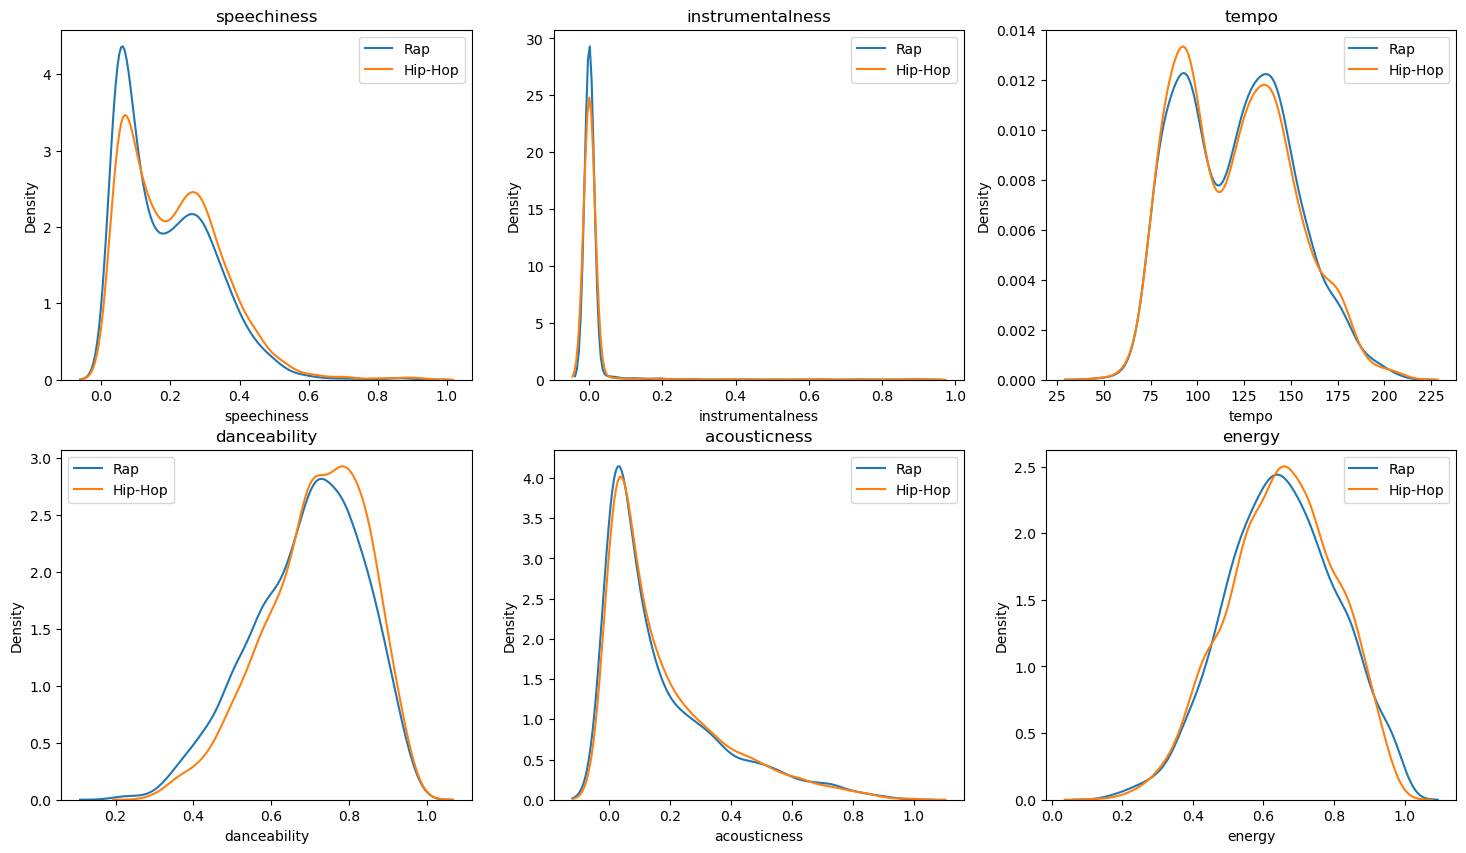

In [23]:
rap = MusicDataset[MusicDataset['music_genre'] == 8]
hip_hop = MusicDataset[MusicDataset['music_genre'] == 6]

plt.figure(figsize=(18, 10))
for i, feature in enumerate(['speechiness', 'instrumentalness', 'tempo', 'danceability', 'acousticness', 'energy']):
    plt.subplot(2, 3, i+1)
    sns.kdeplot(rap[feature], label='Rap')
    sns.kdeplot(hip_hop[feature], label='Hip-Hop')
    plt.title(feature)
    plt.legend()
plt.show()

# Plotting several features related to musicality to show similarities between the two genres, representing each as a graph showing the distribution 
# of points along each feature.

Several of the plotted feature distributions overlap. This suggests that the selected numerical representation may not fully separate these two labels. These plots use the complete labelled dataset for descriptive error analysis; they are not an independent validation set or evidence of a measured performance improvement.


**Alternative-genre errors**

Alternative (label 0) is predicted as several other genres in this dataset. The next plots compare its numerical feature distributions with Country (label 4) and Rock (label 9). Feature overlap is one possible explanation for the confusion, alongside label ambiguity, omitted information, and model limitations.

The bar chart counts the actual model predictions for Alternative tracks in the evaluation subset. It includes both correct predictions and errors and is calculated from the current run rather than a manually entered count table.


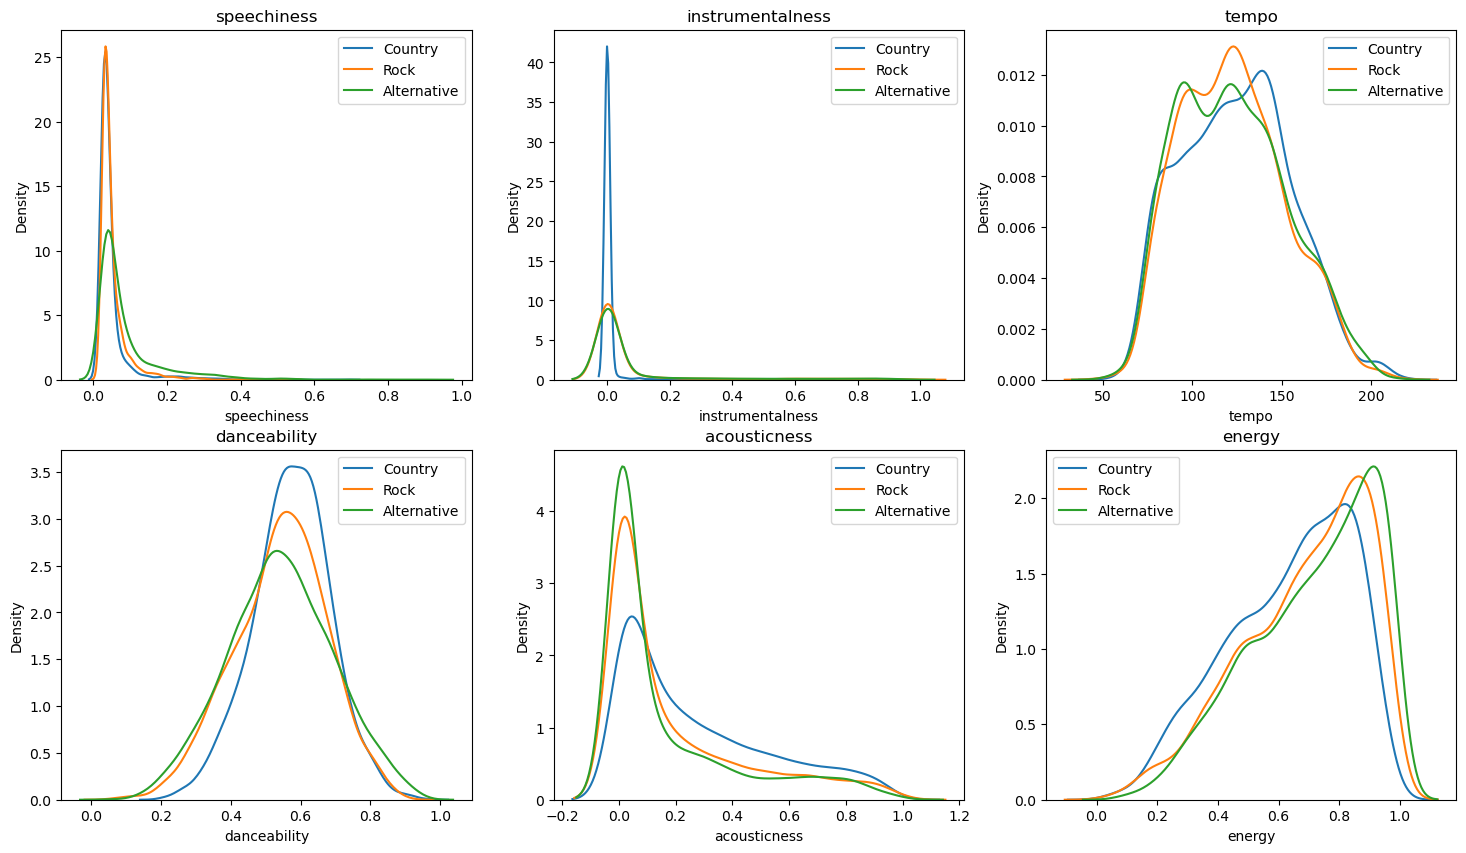

In [24]:
country = MusicDataset[MusicDataset['music_genre'] == 4]
rock = MusicDataset[MusicDataset['music_genre'] == 9]
alternative = MusicDataset[MusicDataset['music_genre'] == 0]

plt.figure(figsize=(18, 10))
for i, feature in enumerate(['speechiness', 'instrumentalness', 'tempo', 'danceability', 'acousticness', 'energy']):
    plt.subplot(2, 3, i+1)
    sns.kdeplot(country[feature], label='Country')
    sns.kdeplot(rock[feature], label='Rock')
    sns.kdeplot(alternative[feature], label='Alternative')
    plt.title(feature)
    plt.legend()
plt.show()

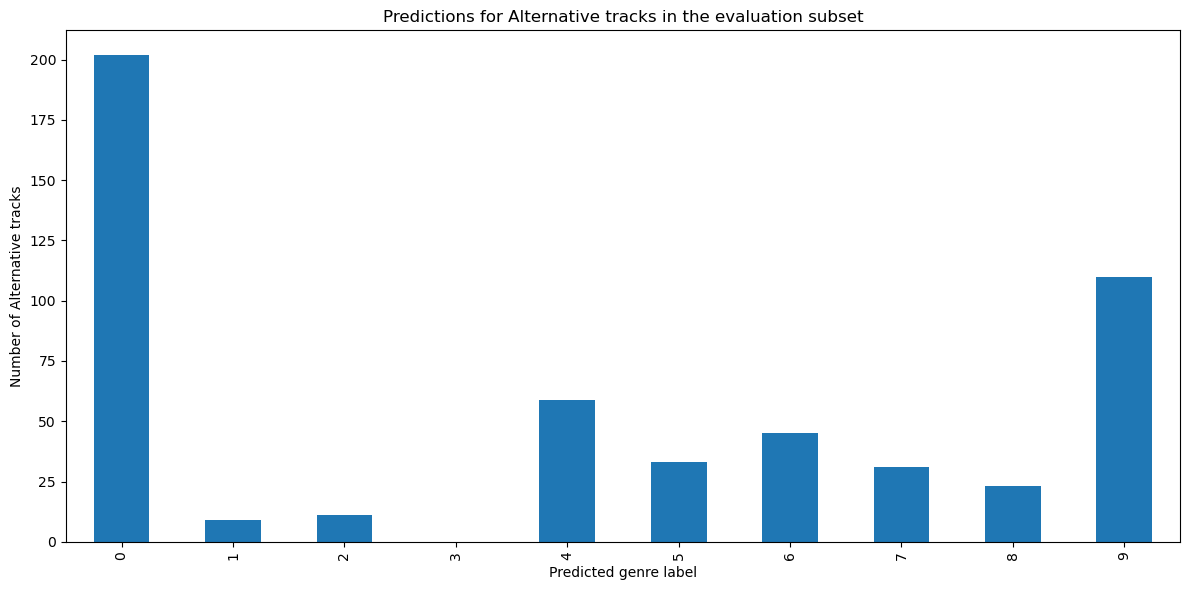

In [25]:
alternative_mask = label_test.eq(0).to_numpy()
alternative_prediction_counts = (
    pd.Series(label_predict_svc[alternative_mask])
    .value_counts()
    .reindex(svc.classes_, fill_value=0)
    .sort_index()
)
alternative_prediction_counts.plot.bar(figsize=(12, 6))
plt.xlabel("Predicted genre label")
plt.ylabel("Number of Alternative tracks")
plt.title("Predictions for Alternative tracks in the evaluation subset")
plt.tight_layout()
plt.show()


**Predicting genres for unlabelled tracks**

The fitted support vector classifier predicts genres for a separate unlabelled dataset. The input columns are aligned with the training schema, and the training-fitted quantile transformer is reused without refitting. The export contains only the track identifier and predicted genre. These predictions have no accompanying ground-truth labels here, so this step does not provide an additional accuracy estimate.


In [26]:
# Match the training feature schema and column order before inference.
inference_features = unlabelled_music.loc[:, features.columns]


In [27]:
# Reuse the training-fitted transformer; do not refit it on new tracks.
inference_features_scaled = sc.transform(inference_features)
predicted_genres = svc.predict(inference_features_scaled)
predicted_genres


array([2, 8, 4, ..., 9, 0, 9], dtype=int64)

In [28]:
music_predictions = pd.DataFrame({
    "instance_id": unlabelled_music["instance_id"],
    "music_genre": predicted_genres,
})


In [29]:
music_predictions


,instance_id,music_genre
0,49290,2
1,81619,8
2,31979,4
3,35985,6
4,25426,0
...,...,...
6485,23196,8
6486,21415,6
6487,46657,9
6488,83211,0


In [30]:
prediction_path = OUTPUT_DIR / "music_predictions.csv"
music_predictions.to_csv(prediction_path, index=False)
print(f"Saved {len(music_predictions):,} predictions to {prediction_path.as_posix()}")


Saved 6,490 predictions to outputs/music_predictions.csv


In [31]:
WineDataset = pd.read_csv(DATA_DIR / "wine_features.csv")
WineDataset


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


**Wine clustering**

The second case study groups wines using numerical chemical measurements. The input contains 13 measurements for each wine; the analysis selects `Alcohol`, `Color_Intensity`, and `Hue` to explore variation in alcohol content and colour-related properties.

No cultivar or quality label is used to fit the clusters. The resulting groups describe patterns in the chosen feature space and should not be interpreted as independently verified wine categories. The dataset source is retained in the references.


In [32]:
WineDataset.describe()
# describe values to roughly gauge scale of each feature

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


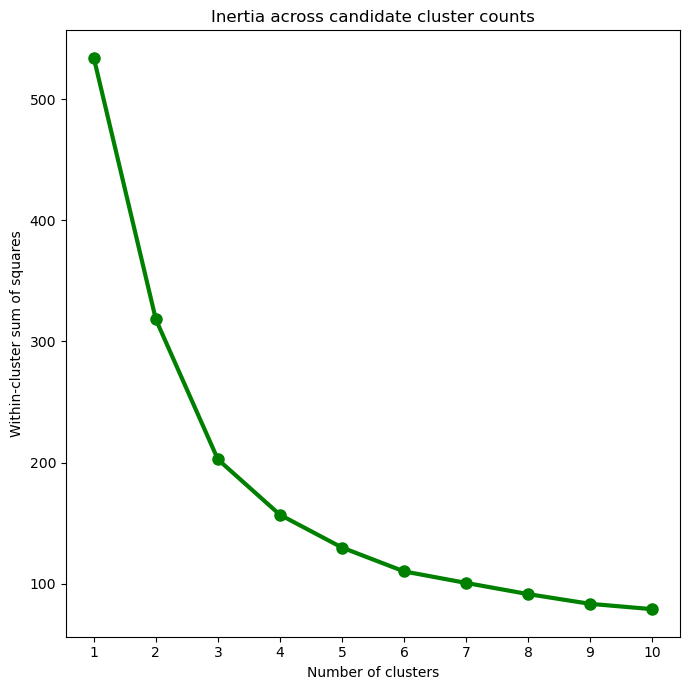

In [33]:
WINE_FEATURES = ["Alcohol", "Color_Intensity", "Hue"]
std_scaler = StandardScaler()
WineDataset_scaled = std_scaler.fit_transform(WineDataset[WINE_FEATURES])

WCSS = []
for cluster_count in range(1, 11):
    model = KMeans(
        n_clusters=cluster_count, init="k-means++", n_init=10,
        random_state=RANDOM_STATE,
    )
    model.fit(WineDataset_scaled)
    WCSS.append(model.inertia_)

plt.figure(figsize=(7, 7))
plt.plot(range(1, 11), WCSS, linewidth=3, markersize=8, marker="o", color="green")
plt.xticks(range(1, 11))
plt.xlabel("Number of clusters")
plt.ylabel("Within-cluster sum of squares")
plt.title("Inertia across candidate cluster counts")
plt.tight_layout()
plt.show()


**Choosing an exploratory cluster count**

K-means assigns records to centroids by distance, so the three selected measurements are standardized before fitting. The same standardized feature matrix is used for the inertia curve and the final clustering model.

The curve shows within-cluster sum of squares for one through ten clusters. Inertia decreases as more clusters are added; an elbow is a heuristic for judging diminishing returns, not proof of a unique correct number. This analysis retains four clusters as an exploratory choice. The elbow-method implementation was informed by the cluster-visualization notebook listed in the references.


In [34]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(WineDataset_scaled)


KMeans(n_clusters=4, n_init=10, random_state=524)

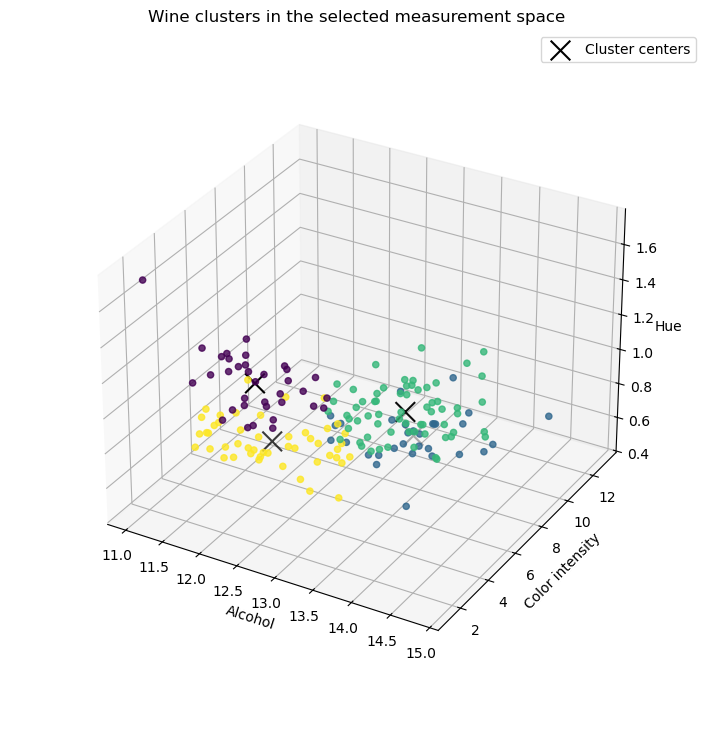

,Alcohol,Color_Intensity,Hue
cluster,,,
0,12.258571,3.023429,1.208286
1,13.276774,8.719677,0.628065
2,13.757812,5.466875,1.062969
3,12.353750,3.631875,0.846583


In [35]:
WinePlot = WineDataset[WINE_FEATURES].to_numpy()
labels = kmeans.labels_
unscaled_centers = std_scaler.inverse_transform(kmeans.cluster_centers_)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(projection="3d")
ax.set_box_aspect(None, zoom=0.85)
ax.scatter(WinePlot[:, 0], WinePlot[:, 1], WinePlot[:, 2], c=labels, alpha=0.8)
ax.scatter(
    unscaled_centers[:, 0], unscaled_centers[:, 1], unscaled_centers[:, 2],
    s=200, marker="x", color="black", label="Cluster centers",
)
ax.set_xlabel("Alcohol")
ax.set_ylabel("Color intensity")
ax.set_zlabel("Hue")
ax.set_title("Wine clusters in the selected measurement space")
ax.legend()
plt.show()

cluster_centers = pd.DataFrame(unscaled_centers, columns=WINE_FEATURES)
cluster_centers.index.name = "cluster"
cluster_centers


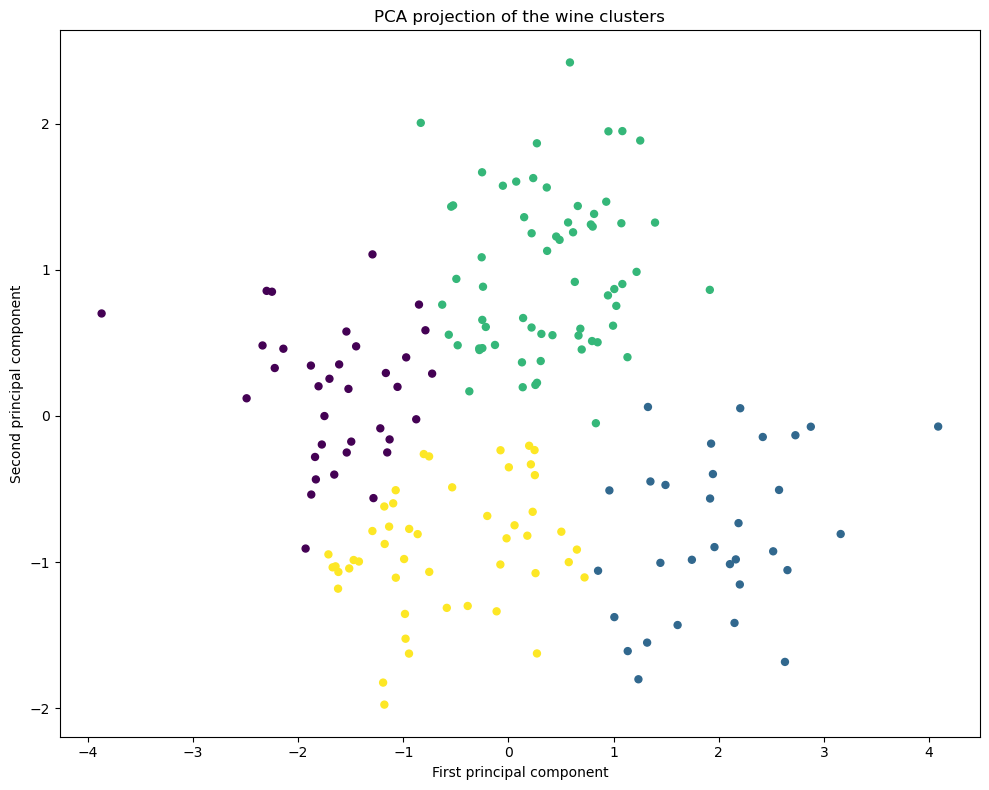

Variance retained by two components: 90.7%


In [36]:
pca = PCA(n_components=2, svd_solver="full")
pca_scaled = pca.fit_transform(WineDataset_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(pca_scaled[:, 0], pca_scaled[:, 1], c=labels, s=25)
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.title("PCA projection of the wine clusters")
plt.tight_layout()
plt.show()
print(f"Variance retained by two components: {pca.explained_variance_ratio_.sum():.1%}")


In [37]:
pca_components = pd.DataFrame(
    pca.components_, columns=WINE_FEATURES, index=["PC1", "PC2"]
)
pca_components


,Alcohol,Color_Intensity,Hue
PC1,0.521423,0.690147,-0.501812
PC2,0.690361,0.004443,0.723452


**Interpreting the clusters with PCA**

PCA projects the three standardized measurements onto two axes for visualization. K-means is fitted in the original three-dimensional standardized space, so PCA changes how the clusters are displayed, not how their labels are assigned.

The component table gives the coefficients of each standardized feature in each principal component. Coefficients with larger absolute values contribute more to that axis; opposite signs indicate opposing directions along it. These coefficients are not themselves feature-to-component correlation coefficients. Component signs can reverse without changing the geometry of the projection.

The centroid table reports the cluster centers in the original measurement units and is the better basis for describing groups as higher or lower in a particular feature. Plot colours and numeric cluster labels are arbitrary. A two-dimensional projection may hide overlap or separation in the omitted direction, so the scatter plot alone cannot establish that four natural populations exist.


**Conclusions and limitations**

The classification workflow compares two numerical-feature baselines and uses confusion matrices, class-wise metrics, and distribution plots to investigate errors. Numerical track attributes alone leave substantial uncertainty between several genre labels. The clustering workflow demonstrates how scaling, feature choice, and projection affect the interpretation of wine groups.

The classifier settings were chosen through manual exploration that reused the evaluation split. Its scores therefore should not be presented as unbiased final test estimates. A stronger follow-up would separate training, model selection, and final evaluation, with preprocessing fitted within each validation fold. Artist-aware splitting could also test whether performance transfers to unseen artists.

Four wine clusters are an exploratory choice based on three selected measurements. This analysis does not establish a uniquely correct cluster count, assess stability across feature sets, or validate groups against external categories.


**References and acknowledgments**

The following dataset, documentation, and tutorial references were used in the original analysis. Tutorial sources are retained to acknowledge the learning and implementation references.

- [Comparing preprocessing transformations](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html)
- [QuantileTransformer API](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html)
- [Original SVM learning reference](https://www.geeksforgeeks.org/support-vector-machine-algorithm/)
- [SVM kernels](https://scikit-learn.org/stable/modules/svm.html#svm-kernels)
- [Original SVM classifier tutorial reference](https://www.kaggle.com/code/prashant111/svm-classifier-tutorial)
- [Original scikit-learn SVM tutorial reference](https://www.datacamp.com/tutorial/svm-classification-scikit-learn-python)
- [Classification report API](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- [Original density-plot learning reference](https://www.geeksforgeeks.org/seaborn-kdeplot-a-comprehensive-guide/)
- [Wine dataset source](https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering)
- [K-means and 3D visualization implementation reference](https://www.kaggle.com/code/naren3256/kmeans-clustering-and-cluster-visualization-in-3d)
- [Original PCA learning reference](https://www.geeksforgeeks.org/principal-component-analysis-pca/)
- [PCA API](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [PCA component interpretation discussion](https://stackoverflow.com/questions/47370795/pca-on-sklearn-how-to-interpret-pca-components)

Additional methodology reference: [Consistent preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
